# 04 — Confidence calibration and final test evaluation
Run beside notebooks 01–03 in the existing `ml` environment, from your `ml_project_final` folder. **No retraining or new image downloads are needed.** Run cells in order. CPU is used. Keep your model files available locally even if they are excluded from GitHub.

This notebook evaluates both architectures and all three seeds using their selected **fine-tuning** checkpoints. It does not replace any checkpoint with a head-only model. Fine-tuning improved validation NLL relative to the best head-only checkpoint in five of the six recorded runs; EfficientNet seed 42 was the exception. This selection limitation is retained and documented.

The steps are: verify provenance → fit six temperatures on calibration cameras → select raw/scaled thresholds on policy cameras → freeze decisions → infer test logits → compute final metrics, plots, and camera-bootstrap intervals → write report notes.

**The test is a final assessment.** Rerunning unchanged code safely reuses cached test logits. Once you have viewed test results, do not change the training, temperature bounds, acceptance rules, or reported metrics to improve those results. Repeated computation is not a new independent test.


## 1. Paths and fixed evaluation choices
A positive temperature rescales a classifier's logits: $p_k(T)=\exp(z_k/T)/\sum_j\exp(z_j/T)$. We fit one scalar per run by minimizing **image-weighted calibration NLL**, without altering weights or labels. $T>1$ softens probabilities and $T<1$ sharpens them. Argmax labels stay unchanged. This follows Guo et al. (2017); calibration can still deteriorate on different cameras.

Policy choices below are specified before test inference: select the highest-coverage confidence threshold whose **observed** accepted error is at most 5%, with at least 100 accepted images from at least five policy cameras. These minimums are pragmatic safeguards for this small project, not a statistical guarantee. A search over observed thresholds can be optimistic on the policy split; only held-out test results assess transfer. No per-category fitting is used because rare categories have few calibration/policy observations.

ECE uses 15 equal-width bins, with 10 and 20 as descriptive sensitivity checks. Multiclass Brier score is the mean **sum** of squared class-probability errors (no division by five). All sample-wide metrics are image-weighted. Camera bootstrap resamples whole test cameras, retaining all their images, and keeps models, temperatures, and thresholds fixed.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, platform, sys, time
import numpy as np
import pandas as pd
from PIL import Image
import PIL
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms
from IPython.display import display

PROJECT_ROOT = None  # Or Path.home()/"Schreibtisch/ml_project_final/wildlife_confidence_project"
if PROJECT_ROOT is None:
    candidates = list(dict.fromkeys(p.resolve() for p in [Path.cwd()/"wildlife_confidence_project",Path.cwd()]
        if (p/"reports/five_categories_v1/training_v1/training_index.json").is_file()))
    if len(candidates)!=1: raise FileNotFoundError("Set PROJECT_ROOT to your wildlife_confidence_project folder.")
    ROOT=candidates[0]
else: ROOT=Path(PROJECT_ROOT).expanduser().resolve()
EXP=ROOT/"data/prepared/five_categories_v1"
TRAIN_REPORT=ROOT/"reports/five_categories_v1/training_v1"
REPORT=ROOT/"reports/five_categories_v1/evaluation_v1"
CACHE=ROOT/"models/five_categories_v1/evaluation_v1"
for p in [REPORT,CACHE]: p.mkdir(parents=True,exist_ok=True)
DEVICE=torch.device("cpu")
torch.set_num_threads(min(4,max(1,torch.get_num_threads())))
CFG={"evaluation_version":1,"target_error":0.05,"minimum_accepted":100,
     "minimum_accepted_cameras":5,"temperature_bounds":[0.01,100.0],
     "ece_bins":15,"ece_sensitivity_bins":[10,20],"bootstrap_repeats":2000,
     "bootstrap_seed":20261026,"test_batch_size":4,"num_workers":0,
     "threshold_rule":"max coverage among full tied-confidence groups satisfying empirical policy constraints",
     "checkpoint_rule":"notebook03 best_finetune only"}
def now(): return datetime.now(timezone.utc).isoformat()
def sha(p):
    h=hashlib.sha256()
    with Path(p).open("rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""): h.update(block)
    return h.hexdigest()
def jtext(x): return json.dumps(x,indent=2,sort_keys=True,allow_nan=False)+"\n"
def write(p,s):
    p=Path(p);tmp=Path(str(p)+".tmp");tmp.write_text(s,encoding="utf-8");tmp.replace(p)
def freeze(p,s):
    if p.exists() and p.read_text()!=s: raise ValueError(f"Frozen evaluation differs: {p}. Do not overwrite an evaluated protocol.")
    if not p.exists(): write(p,s)
def table(name,rows):
    df=rows if isinstance(rows,pd.DataFrame) else pd.DataFrame(rows)
    write(REPORT/name,df.to_csv(index=False));return df
print("Project:",ROOT,"| CPU | torch:",torch.__version__)


Project: /home/fia/Schreibtisch/ml_project_final/wildlife_confidence_project | CPU | torch: 2.14.0+cu130


## 2. Verify all six runs and their exported development logits
Checks bind the evaluation to the selected checkpoints, class order, image IDs, labels, cameras, sequences and frozen input hashes. Only calibration and policy logits are loaded here. Test labels are read as part of the manifest integrity checks; they are not used by any fitting or policy-selection function.


In [2]:
protocol=json.loads((EXP/"protocol.json").read_text())
if protocol.get("pipeline_kind")!="megadetector_assisted_single_v1":
    raise ValueError("This notebook requires the unified MegaDetector-assisted pipeline.")
index=json.loads((TRAIN_REPORT/"training_index.json").read_text())
train_cfg=json.loads((TRAIN_REPORT/"training_protocol.json").read_text())
classes_record=json.loads((EXP/"classes.json").read_text())
CLASSES=classes_record["classes"];K=len(CLASSES)
assert CLASSES==["coyote","deer","fox","rabbit","skunk"]
assert classes_record["class_to_idx"]=={s:i for i,s in enumerate(CLASSES)}
assert index["classes"]==CLASSES and index["all_planned_runs_complete"]
assert index["test_predictions_computed"] is False
assert index["training_sha256"]==sha(TRAIN_REPORT/"training_protocol.json")
assert index["protocol_sha256"]==sha(EXP/"protocol.json")
assert index["subset_sha256"]==sha(EXP/"subset_manifest.csv")
assert train_cfg["ready_manifest_sha256"]==sha(EXP/"training_ready_manifest.csv")
for name,expected in protocol["input_sha256"].items():
    assert sha(ROOT/"data/prepared"/name)==expected, name
for package,version in [("torch",str(torch.__version__)),("torchvision",str(torchvision.__version__))]:
    if train_cfg["versions"][package]!=version:
        raise ValueError(f"Use the notebook03 environment: {package} was {train_cfg['versions'][package]}, now {version}")
manifest=pd.read_csv(EXP/"training_ready_manifest.csv",dtype=str,keep_default_na=False)
base=pd.read_csv(EXP/"subset_manifest.csv",dtype=str,keep_default_na=False)
assert manifest[base.columns].equals(base)
manifest["label"]=manifest.label.astype(int)
assert manifest.image_id.is_unique and manifest.seq_id.is_unique
assert manifest.groupby("location").split.nunique().eq(1).all()
assert manifest.label.eq(manifest.class_name.map({c:i for i,c in enumerate(CLASSES)})).all()
for col in ["source_sha256","cache_sha256"]:
    assert manifest[col].ne("").all() and manifest.groupby(col).split.nunique().le(1).all()
expected={(m,s) for m in train_cfg["models"] for s in train_cfg["planned_seeds"]}
RUNS=index["completed_runs"]
assert len(RUNS)==6 and {(r["model"],int(r["seed"])) for r in RUNS}==expected

def safe_path(relative):
    p=(ROOT/relative).resolve()
    if not p.is_relative_to(ROOT): raise ValueError("Path leaves project root")
    return p

def check_arrays(a,frame):
    assert a["logits"].shape==(len(frame),K) and np.isfinite(a["logits"]).all()
    for key,col,dtype in [("image_ids","image_id",str),("labels","label",np.int64),
                          ("locations","location",str),("seq_ids","seq_id",str)]:
        assert np.array_equal(a[key],frame[col].to_numpy(dtype=dtype)),key
    assert np.array_equal(a["class_names"],np.array(CLASSES))

def load_development(run,split):
    run_dir=safe_path(run["run_relative_path"])
    entry=run["exports"][split];p=run_dir/entry["file"]
    assert p.parent==run_dir and sha(p)==entry["sha256"]
    with np.load(p,allow_pickle=False) as saved: a={k:saved[k].copy() for k in saved.files}
    frame=manifest.loc[manifest.split.eq(split)].reset_index(drop=True)
    check_arrays(a,frame)
    for key,value in [("checkpoint_sha256",run["checkpoint_sha256"]),
                      ("training_sha256",index["training_sha256"]),("subset_sha256",index["subset_sha256"]),
                      ("model_name",run["model"]),("seed",int(run["seed"]))]:
        assert a[key].item()==value,key
    return a

DEV={}
for run in RUNS:
    key=(run["model"],int(run["seed"]))
    run_dir=safe_path(run["run_relative_path"])
    assert run["checkpoint_file"]=="best_finetune.pt"
    assert sha(run_dir/run["checkpoint_file"])==run["checkpoint_sha256"]
    DEV[key]={s:load_development(run,s) for s in ["calibration","policy"]}
    print("Verified:",*key)
EVAL_INPUT={"settings":CFG,"training_sha256":index["training_sha256"],
    "protocol_sha256":index["protocol_sha256"],"subset_sha256":index["subset_sha256"],
    "ready_manifest_sha256":sha(EXP/"training_ready_manifest.csv"),
    "runs":[{"model":r["model"],"seed":int(r["seed"]),"checkpoint_sha256":r["checkpoint_sha256"],
             "development_exports":r["exports"]} for r in RUNS],
    "versions":{"python":sys.version.split()[0],"torch":str(torch.__version__),
                "torchvision":str(torchvision.__version__),"numpy":np.__version__,"pandas":pd.__version__,"pillow":PIL.__version__}}
freeze(REPORT/"evaluation_protocol.json",jtext(EVAL_INPUT))
EVAL_SHA=sha(REPORT/"evaluation_protocol.json")
print("Frozen evaluation:",EVAL_SHA)


Verified: mobilenet_v3_large 42
Verified: efficientnet_b0 42
Verified: mobilenet_v3_large 123
Verified: efficientnet_b0 123
Verified: mobilenet_v3_large 2026
Verified: efficientnet_b0 2026
Frozen evaluation: ec12b85548777fada41c2f84eacb0e51da5a3ed9d6881ac80adb045505f4df04


## 3. Metric definitions and temperature fitting
NLL uses a stable log-softmax calculation. Accuracy and macro-F1 use the original logits' argmax, avoiding numerical tie changes after extreme scaling. ECE is the image-weighted absolute difference between mean confidence and accuracy in each confidence bin; empty bins contribute zero. ECE depends on binning and is not a complete calibration measure.

We optimize inverse temperature $\beta=1/T$. NLL is convex in this scalar. A deterministic derivative bisection finds the bounded optimum in $T\in[0.01,100]$, including endpoint checks; $T=1$ is retained if numerical rounding would worsen the calibration objective. Boundary solutions are flagged, not silently hidden. These bounds are fixed before testing. Calibration-split improvement is fitted performance, not independent evidence of generalization.


In [3]:
def probabilities(logits,T=1.0):
    z=np.asarray(logits,dtype=np.float64)/float(T)
    z-=z.max(axis=1,keepdims=True)
    logp=z-np.log(np.exp(z).sum(axis=1,keepdims=True))
    return np.exp(logp),logp

def reliability(logits,y,T,bins):
    p,_=probabilities(logits,T);conf=p.max(1);correct=logits.argmax(1)==y
    b=np.minimum((conf*bins).astype(int),bins-1)
    count=np.bincount(b,minlength=bins)
    cs=np.bincount(b,weights=conf,minlength=bins)
    hits=np.bincount(b,weights=correct,minlength=bins)
    return pd.DataFrame({"bin":np.arange(bins),"lower":np.arange(bins)/bins,
        "upper":(np.arange(bins)+1)/bins,"count":count,
        "confidence":np.divide(cs,count,out=np.full(bins,np.nan),where=count>0),
        "accuracy":np.divide(hits,count,out=np.full(bins,np.nan),where=count>0)})

def metrics(logits,y,T=1.0):
    p,lp=probabilities(logits,T);pred=logits.argmax(1)
    cm=np.bincount(y*K+pred,minlength=K*K).reshape(K,K)
    den=cm.sum(0)+cm.sum(1)
    f1=np.divide(2*np.diag(cm),den,out=np.zeros(K,dtype=float),where=den>0)
    rel=reliability(logits,y,T,CFG["ece_bins"])
    return {"nll":float(-lp[np.arange(len(y)),y].mean()),
        "accuracy":float((pred==y).mean()),"macro_f1":float(f1.mean()),
        "brier":float(((p-np.eye(K)[y])**2).sum(1).mean()),
        "ece":float((rel["count"]*(rel.confidence-rel.accuracy).abs()).sum()/len(y))}

def fit_temperature(logits,y):
    z=np.asarray(logits,dtype=np.float64)
    loT,hiT=CFG["temperature_bounds"];lo,hi=1/hiT,1/loT
    def derivative(beta):
        p,_=probabilities(z,1/beta)
        return float(((p*z).sum(1)-z[np.arange(len(y)),y]).mean())
    if derivative(lo)>=0: beta=lo
    elif derivative(hi)<=0: beta=hi
    else:
        for _ in range(90):
            mid=(lo+hi)/2
            if derivative(mid)>0:hi=mid
            else:lo=mid
        beta=(lo+hi)/2
    T=1/beta
    raw=metrics(z,y,1)["nll"];scaled=metrics(z,y,T)["nll"]
    if scaled>raw: T=1.0;scaled=raw
    return {"temperature":float(T),"calibration_nll_raw":raw,"calibration_nll_scaled":scaled,
            "at_temperature_boundary":bool(np.isclose(T,loT) or np.isclose(T,hiT))}

TEMPERATURES={};temperature_rows=[]
for key,data in DEV.items():
    a=data["calibration"];result=fit_temperature(a["logits"],a["labels"])
    TEMPERATURES[key]=result["temperature"]
    temperature_rows.append({"model":key[0],"seed":key[1],**result})
temperature_summary=table("temperature_summary.csv",temperature_rows)
display(temperature_summary)


,model,seed,temperature,calibration_nll_raw,calibration_nll_scaled,at_temperature_boundary
0,mobilenet_v3_large,42,1.649763,0.292384,0.254989,False
1,efficientnet_b0,42,1.169279,0.316746,0.312562,False
2,mobilenet_v3_large,123,1.248080,0.302094,0.295346,False
3,efficientnet_b0,123,1.329853,0.302637,0.288767,False
4,mobilenet_v3_large,2026,1.356728,0.386987,0.370021,False
5,efficientnet_b0,2026,1.600185,0.317582,0.283185,False


## 4. Fit the acceptance rules on policy cameras and freeze them
Confidence is the maximum class probability. Accept an image if confidence ≥ threshold; all other images need manual review. The raw and scaled variants each receive a separately fitted threshold under identical constraints. Scaling preserves each image's predicted category, but can reorder confidence across images in a multiclass problem.

We evaluate full groups of tied confidence scores, so the selected threshold reproduces its recorded accepted count. Error is mistakes divided by accepted images; coverage is accepted images divided by all images. If no candidate qualifies, the policy accepts none and its accepted error is **undefined**, not zero. Policy labels never influence temperature fitting. Thresholds and temperatures are frozen to disk before any test inference.


In [4]:
def choose_policy(logits,y,locations,T):
    p,_=probabilities(logits,T);conf=p.max(1);wrong=(logits.argmax(1)!=y)
    order=np.argsort(-conf,kind="stable");scores=conf[order]
    ends=np.r_[np.flatnonzero(scores[:-1]!=scores[1:]),len(scores)-1]
    errors=np.cumsum(wrong[order]);seen=set();camera_counts=np.zeros(len(order),dtype=int)
    for i,j in enumerate(order):
        seen.add(str(locations[j]));camera_counts[i]=len(seen)
    candidates=pd.DataFrame({"threshold":scores[ends],"accepted":ends+1,
        "errors":errors[ends],"accepted_cameras":camera_counts[ends]})
    candidates["coverage"]=candidates.accepted/len(y)
    candidates["accepted_error"]=candidates.errors/candidates.accepted
    good=candidates.loc[(candidates.accepted>=CFG["minimum_accepted"]) &
        (candidates.accepted_cameras>=CFG["minimum_accepted_cameras"]) &
        (candidates.accepted_error<=CFG["target_error"])]
    if good.empty:
        return {"status":"no_qualifying_threshold","threshold":None,"accepted":0,
                "errors":0,"accepted_cameras":0,"coverage":0.0,"accepted_error":None},candidates
    r=good.iloc[-1]
    return {"status":"selected","threshold":float(r.threshold),"accepted":int(r.accepted),
        "errors":int(r.errors),"accepted_cameras":int(r.accepted_cameras),
        "coverage":float(r.coverage),"accepted_error":float(r.accepted_error)},candidates

POLICIES={};policy_rows=[];frozen_runs=[]
for run in RUNS:
    key=(run["model"],int(run["seed"]));a=DEV[key]["policy"];pol={}
    for variant,T in [("raw",1.0),("scaled",TEMPERATURES[key])]:
        result,candidates=choose_policy(a["logits"],a["labels"],a["locations"],T)
        pol[variant]=result
        table(f"policy_candidates_{key[0]}_seed{key[1]}_{variant}.csv",candidates)
        policy_rows.append({"model":key[0],"seed":key[1],"variant":variant,"temperature":T,**result})
    POLICIES[key]=pol
    frozen_runs.append({"model":key[0],"seed":key[1],"checkpoint_sha256":run["checkpoint_sha256"],
                        "temperature":TEMPERATURES[key],"policies":pol})
freeze(REPORT/"frozen_calibration_and_policies.json",jtext({"evaluation_sha256":EVAL_SHA,"runs":frozen_runs}))
DECISION_SHA=sha(REPORT/"frozen_calibration_and_policies.json")
policy_summary=table("policy_summary.csv",policy_rows)
display(policy_summary)
print("Decisions frozen BEFORE test inference:",DECISION_SHA)


,model,seed,variant,temperature,status,threshold,accepted,errors,accepted_cameras,coverage,accepted_error
0,mobilenet_v3_large,42,raw,1.000000,selected,0.804553,1247,62,13,0.831333,0.049719
1,mobilenet_v3_large,42,scaled,1.649763,selected,0.624959,1257,62,13,0.838000,0.049324
2,efficientnet_b0,42,raw,1.000000,selected,0.677154,1255,62,13,0.836667,0.049402
3,efficientnet_b0,42,scaled,1.169279,selected,0.634495,1255,62,13,0.836667,0.049402
4,mobilenet_v3_large,123,raw,1.000000,selected,0.581468,1325,66,13,0.883333,0.049811
5,mobilenet_v3_large,123,scaled,1.248080,selected,0.529240,1328,66,13,0.885333,0.049699
6,efficientnet_b0,123,raw,1.000000,selected,0.586897,1300,65,13,0.866667,0.050000
7,efficientnet_b0,123,scaled,1.329853,selected,0.529934,1300,65,13,0.866667,0.050000
8,mobilenet_v3_large,2026,raw,1.000000,selected,0.736109,1191,59,13,0.794000,0.049538
9,mobilenet_v3_large,2026,scaled,1.356728,selected,0.631822,1200,60,13,0.800000,0.050000


Decisions frozen BEFORE test inference: 918abcd69c0297ed22741d334355f68363fc144f3d8d1ac9220268e8c5a30ec1


## 5. Run the final test forward passes
Each selected checkpoint is loaded on CPU with `weights_only=True` and strict state-dictionary loading. Models are constructed with `weights=None`, so no pretrained download is needed. Test transforms match notebook03 evaluation: RGB tensor plus ImageNet normalization, with no random augmentation. The 224px images already contain notebook02 cropping/padding.

Inference uses `model.eval()` and `torch.inference_mode()`. It does not update weights or BatchNorm statistics. Each run's test logits are saved atomically with IDs and provenance. Reruns verify and reuse them. No image is silently skipped. This stage should be substantially shorter than training, although file checks and six CPU forward passes still take time.


In [5]:
test_frame=manifest.loc[manifest.split.eq("test")].reset_index(drop=True)
assert len(test_frame)>0
for i,row in enumerate(test_frame.itertuples(index=False),1):
    p=safe_path(row.cache_relative_path)
    assert p.is_file() and sha(p)==row.cache_sha256,row.image_id
    with Image.open(p) as im:
        assert im.size==(224,224) and im.mode=="RGB" and im.format=="PNG"
        im.load()
    if i%500==0:print(f"Verified {i}/{len(test_frame)} test inputs",flush=True)
class TestDataset(Dataset):
    transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
    def __len__(self):return len(test_frame)
    def __getitem__(self,i):
        row=test_frame.iloc[i]
        with Image.open(safe_path(row.cache_relative_path)) as im: x=self.transform(im.convert("RGB"))
        return x,row.image_id

def build_model(name):
    if name=="mobilenet_v3_large": model=models.mobilenet_v3_large(weights=None)
    elif name=="efficientnet_b0": model=models.efficientnet_b0(weights=None)
    else: raise ValueError(name)
    model.classifier[-1]=nn.Linear(model.classifier[-1].in_features,K)
    return model

TEST={};test_exports=[]
for run in RUNS:
    key=(run["model"],int(run["seed"]));destination=CACHE/f"{key[0]}_seed{key[1]}_test_logits.npz"
    provenance={"checkpoint_sha256":run["checkpoint_sha256"],"evaluation_sha256":EVAL_SHA,
                "decisions_sha256":DECISION_SHA,"model_name":key[0],"seed":key[1]}
    started=time.perf_counter()
    if destination.exists():
        with np.load(destination,allow_pickle=False) as saved:a={k:saved[k].copy() for k in saved.files}
        for k,v in provenance.items():assert a[k].item()==v,k
        check_arrays(a,test_frame)
        print("Reusing verified test logits:",*key,flush=True)
    else:
        print("Test inference:",*key,flush=True)
        checkpoint=torch.load(safe_path(run["run_relative_path"])/run["checkpoint_file"],map_location="cpu",weights_only=True)
        assert checkpoint["training_sha256"]==index["training_sha256"]
        assert checkpoint["classes"]==CLASSES and checkpoint["model_name"]==key[0] and checkpoint["seed"]==key[1]
        assert not checkpoint.get("pilot_only",False)
        model=build_model(key[0]).to(DEVICE)
        model.load_state_dict(checkpoint["state_dict"],strict=True);model.eval()
        parts=[];ids=[]
        loader=DataLoader(TestDataset(),batch_size=CFG["test_batch_size"],shuffle=False,num_workers=0)
        with torch.inference_mode():
            for batch,(x,image_ids) in enumerate(loader,1):
                out=model(x.to(DEVICE)).cpu().numpy()
                assert out.shape==(len(image_ids),K) and np.isfinite(out).all()
                parts.append(out);ids.extend(image_ids)
                if batch%100==0:print(f"  {batch}/{len(loader)} batches",flush=True)
        a={"logits":np.concatenate(parts),"image_ids":np.asarray(ids,dtype=str),
           "labels":test_frame.label.to_numpy(dtype=np.int64),"locations":test_frame.location.to_numpy(dtype=str),
           "seq_ids":test_frame.seq_id.to_numpy(dtype=str),"class_names":np.asarray(CLASSES),
           **{k:np.asarray(v) for k,v in provenance.items()}}
        check_arrays(a,test_frame)
        tmp=Path(str(destination)+".tmp")
        with tmp.open("wb") as f:np.savez_compressed(f,**a)
        tmp.replace(destination)
        del model,checkpoint
        print(f"  Saved {len(ids)} predictions in {(time.perf_counter()-started)/60:.1f} minutes",flush=True)
    TEST[key]=a
    test_exports.append({"model":key[0],"seed":key[1],"file":str(destination.relative_to(ROOT)),"sha256":sha(destination)})
write(REPORT/"test_exports.json",jtext({"evaluation_sha256":EVAL_SHA,"decisions_sha256":DECISION_SHA,"exports":test_exports}))


Verified 500/2664 test inputs
Verified 1000/2664 test inputs
Verified 1500/2664 test inputs
Verified 2000/2664 test inputs
Verified 2500/2664 test inputs
Test inference: mobilenet_v3_large 42
  100/666 batches
  200/666 batches
  300/666 batches
  400/666 batches
  500/666 batches
  600/666 batches
  Saved 2664 predictions in 1.3 minutes
Test inference: efficientnet_b0 42
  100/666 batches
  200/666 batches
  300/666 batches
  400/666 batches
  500/666 batches
  600/666 batches
  Saved 2664 predictions in 1.3 minutes
Test inference: mobilenet_v3_large 123
  100/666 batches
  200/666 batches
  300/666 batches
  400/666 batches
  500/666 batches
  600/666 batches
  Saved 2664 predictions in 0.7 minutes
Test inference: efficientnet_b0 123
  100/666 batches
  200/666 batches
  300/666 batches
  400/666 batches
  500/666 batches
  600/666 batches
  Saved 2664 predictions in 1.2 minutes
Test inference: mobilenet_v3_large 2026
  100/666 batches
  200/666 batches
  300/666 batches
  400/666 ba

## 6. Final classification, calibration and selective-prediction results
All six runs remain in the analysis. Raw and scaled accuracy/macro-F1 must be identical: temperature changes probabilities, not class labels. A lower independent test NLL/Brier/ECE after scaling is evidence of improvement on these cameras; improvement is not forced.

`accepted_error` is the error rate among automated predictions. `coverage` is the automated fraction; `manual_review_fraction=1-coverage`. `target_met_on_test` is descriptive and may be false. Do not adjust a threshold after seeing this. No-acceptance error and target status are undefined. Per-category accepted errors can be unreliable with tiny accepted counts; inspect counts alongside rates.


In [6]:
def selective(logits,y,locations,T,policy):
    conf=probabilities(logits,T)[0].max(1)
    accept=np.zeros(len(y),dtype=bool) if policy["threshold"] is None else conf>=policy["threshold"]
    wrong=logits.argmax(1)!=y;n=int(accept.sum());err=int(wrong[accept].sum())
    return {"accepted":n,"accepted_errors":err,"coverage":n/len(y),"manual_review_fraction":1-n/len(y),
        "accepted_error":err/n if n else np.nan,
        "accepted_cameras":len(np.unique(locations[accept])),
        "target_met_on_test":bool(err/n<=CFG["target_error"]) if n else None},accept

result_rows=[];class_rows=[];prediction_rows=[];ece_rows=[]
for key,a in TEST.items():
    z,y,loc=a["logits"],a["labels"],a["locations"];pred=z.argmax(1)
    cm=np.bincount(y*K+pred,minlength=K*K).reshape(K,K)
    for variant,T in [("raw",1.),("scaled",TEMPERATURES[key])]:
        score=metrics(z,y,T);policy=POLICIES[key][variant]
        sel,accept=selective(z,y,loc,T,policy)
        result_rows.append({"model":key[0],"seed":key[1],"variant":variant,"temperature":T,
            "images":len(y),"cameras":len(np.unique(loc)),"threshold":policy["threshold"],**score,**sel})
        p,_=probabilities(z,T)
        for c,name in enumerate(CLASSES):
            tp=cm[c,c];support=cm[c].sum();predicted=cm[:,c].sum()
            group=(y==c)&accept;n=int(group.sum())
            class_rows.append({"model":key[0],"seed":key[1],"variant":variant,"class":name,
                "support":int(support),"predicted_count":int(predicted),
                "precision":tp/predicted if predicted else np.nan,"recall":tp/support if support else np.nan,
                "f1":2*tp/(support+predicted) if support+predicted else 0.,
                "accepted":n,"coverage_within_true_class":n/support if support else np.nan,
                "accepted_error":float((pred[group]!=y[group]).mean()) if n else np.nan})
        for bins in [10,15,20]:
            rel=reliability(z,y,T,bins)
            ece_rows.append({"model":key[0],"seed":key[1],"variant":variant,"bins":bins,
                "ece":float((rel["count"]*(rel.confidence-rel.accuracy).abs()).sum()/len(y))})
        prediction_rows.append(pd.DataFrame({"model":key[0],"seed":key[1],"variant":variant,
            "image_id":a["image_ids"],"location":loc,"true_class":[CLASSES[i] for i in y],
            "predicted_class":[CLASSES[i] for i in pred],"confidence":p.max(1),"correct":pred==y,"accepted":accept}))
results=table("test_results.csv",result_rows)
for key in TEST:
    r=results.loc[(results.model==key[0])&(results.seed==key[1])]
    assert r.accuracy.nunique()==1 and r.macro_f1.nunique()==1
per_class=table("test_per_class.csv",class_rows)
table("test_predictions.csv",pd.concat(prediction_rows,ignore_index=True))
table("ece_bin_sensitivity.csv",ece_rows)
summary=results.groupby(["model","variant"])[["accuracy","macro_f1","nll","brier","ece","coverage","accepted_error"]].agg(["mean","std"])
write(REPORT/"test_seed_summary.csv",summary.to_csv())
display(results.round(4));display(summary.round(4))
print("Mean/std summarize training seeds, not independent camera-split replications.")


,model,seed,variant,temperature,images,cameras,threshold,nll,accuracy,macro_f1,brier,ece,accepted,accepted_errors,coverage,manual_review_fraction,accepted_error,accepted_cameras,target_met_on_test
0,mobilenet_v3_large,42,raw,1.0000,2664,26,0.8046,0.4712,0.8382,0.7550,0.2300,0.0681,2144,137,0.8048,0.1952,0.0639,26,False
1,mobilenet_v3_large,42,scaled,1.6498,2664,26,0.6250,0.4110,0.8382,0.7550,0.2126,0.0198,2162,143,0.8116,0.1884,0.0661,26,False
2,efficientnet_b0,42,raw,1.0000,2664,26,0.6772,0.5260,0.7924,0.7425,0.2688,0.0460,2032,158,0.7628,0.2372,0.0778,26,False
3,efficientnet_b0,42,scaled,1.1693,2664,26,0.6345,0.5141,0.7924,0.7425,0.2650,0.0258,2036,158,0.7643,0.2357,0.0776,26,False
4,mobilenet_v3_large,123,raw,1.0000,2664,26,0.5815,0.5060,0.8033,0.7201,0.2557,0.0519,2195,220,0.8239,0.1761,0.1002,26,False
5,mobilenet_v3_large,123,scaled,1.2481,2664,26,0.5292,0.4857,0.8033,0.7201,0.2501,0.0258,2192,213,0.8228,0.1772,0.0972,26,False
6,efficientnet_b0,123,raw,1.0000,2664,26,0.5869,0.4254,0.8416,0.7797,0.2168,0.0288,2287,200,0.8585,0.1415,0.0875,26,False
7,efficientnet_b0,123,scaled,1.3299,2664,26,0.5299,0.4208,0.8416,0.7797,0.2152,0.0221,2267,192,0.8510,0.1490,0.0847,26,False
8,mobilenet_v3_large,2026,raw,1.0000,2664,26,0.7361,0.5566,0.7947,0.7104,0.2771,0.0587,1999,147,0.7504,0.2496,0.0735,26,False
9,mobilenet_v3_large,2026,scaled,1.3567,2664,26,0.6318,0.5265,0.7947,0.7104,0.2683,0.0240,2004,149,0.7523,0.2477,0.0744,26,False


accuracy         macro_f1             nll          \
                               mean     std     mean     std    mean     std   
model              variant                                                     
efficientnet_b0    raw       0.8198  0.0251   0.7557  0.0208  0.4867  0.0538   
                   scaled    0.8198  0.0251   0.7557  0.0208  0.4625  0.0474   
mobilenet_v3_large raw       0.8121  0.0231   0.7285  0.0234  0.5113  0.0430   
                   scaled    0.8121  0.0231   0.7285  0.0234  0.4744  0.0585   

                             brier             ece         coverage          \
                              mean     std    mean     std     mean     std   
model              variant                                                    
efficientnet_b0    raw      0.2406  0.0262  0.0455  0.0166   0.8179  0.0495   
                   scaled   0.2350  0.0265  0.0227  0.0029   0.8174  0.0466   
mobilenet_v3_large raw      0.2543  0.0236  0.0596  0.0081   0.7930  0.0382   
                   scaled   0.2437  0.0284  0.0232  0.0031   0.7955  0.0379   

                           accepted_error          
                                     mean     std  
model              variant                         
efficientnet_b0    raw             0.0808  0.0058  
                   scaled          0.0788  0.0054  
mobilenet_v3_large raw             0.0792  0.0188  
                   scaled          0.0792  0.0161

Mean/std summarize training seeds, not independent camera-split replications.


## 7. Paired camera bootstrap uncertainty
We resample the same test-camera IDs with replacement for every model, seed and calibration variant, including all images belonging to each sampled camera. This preserves within-camera dependence and pairs comparisons. Sufficient statistics make 2,000 replicates efficient. Each replicate recomputes image-weighted metrics, including ECE and macro-F1.

Intervals are 2.5th–97.5th percentile camera-bootstrap intervals. They are conditional on the fixed trained models, fitted temperatures, selected thresholds, and available test cameras. They do **not** include uncertainty from retraining, refitting calibration/policy data, alternative splits, or detector pretraining. They are exploratory with few cameras. Replicates with no accepted images have undefined accepted error; their count is reported. Macro-F1 uses all five fixed classes, assigning F1=0 when a class has no truth or predictions in a replicate.

Paired contrasts report scaled minus raw and EfficientNet minus MobileNet (averaged across the three predefined seeds within each replicate). Negative NLL/Brier/ECE deltas favour the first named method; positive accuracy/F1/coverage deltas favour it. Accepted error must be interpreted jointly with coverage because accepted populations differ.


In [7]:
cameras=np.unique(test_frame.location.to_numpy(dtype=str));C=len(cameras)
if C<2:raise ValueError("Camera bootstrap needs multiple test cameras")
cam_idx=np.searchsorted(cameras,test_frame.location.to_numpy(dtype=str))
rng=np.random.default_rng(CFG["bootstrap_seed"])
# Each row contains camera multiplicities for one shared bootstrap draw.
W=rng.multinomial(C,np.full(C,1/C),size=CFG["bootstrap_repeats"]).astype(float)
METRICS=["accuracy","nll","brier","ece","macro_f1","coverage","accepted_error"]
BOOT={}
def bootstrap_metrics(a,T,accept):
    z,y=a["logits"],a["labels"];p,lp=probabilities(z,T);pred=z.argmax(1);correct=pred==y
    conf=p.max(1);bins=CFG["ece_bins"];bi=np.minimum((conf*bins).astype(int),bins-1)
    # Column blocks: n, correct, NLL, Brier, accepted, accepted wrong, confusion, bin count/confidence/correct.
    values=np.zeros((len(y),6+K*K+3*bins))
    values[:,:6]=np.column_stack([np.ones(len(y)),correct,-lp[np.arange(len(y)),y],
        ((p-np.eye(K)[y])**2).sum(1),accept,accept&~correct])
    values[np.arange(len(y)),6+y*K+pred]=1
    start=6+K*K
    values[np.arange(len(y)),start+bi]=1
    values[np.arange(len(y)),start+bins+bi]=conf
    values[np.arange(len(y)),start+2*bins+bi]=correct
    agg=np.zeros((C,values.shape[1]));np.add.at(agg,cam_idx,values)
    s=W@agg;n=s[:,0];cm=s[:,6:6+K*K].reshape(-1,K,K)
    den=cm.sum(1)+cm.sum(2)
    f1=np.divide(2*np.diagonal(cm,axis1=1,axis2=2),den,out=np.zeros_like(den),where=den>0).mean(1)
    # count * |confidence mean - correct mean| = |confidence sum - correct sum|.
    ece=np.abs(s[:,start+bins:start+2*bins]-s[:,start+2*bins:start+3*bins]).sum(1)/n
    err=np.divide(s[:,5],s[:,4],out=np.full(len(n),np.nan),where=s[:,4]>0)
    return dict(zip(METRICS,[s[:,1]/n,s[:,2]/n,s[:,3]/n,ece,f1,s[:,4]/n,err]))

def interval(values):
    finite=values[np.isfinite(values)]
    return (float(np.quantile(finite,.025)),float(np.quantile(finite,.975)),len(finite)) if len(finite) else (np.nan,np.nan,0)
ci_rows=[]
for key,a in TEST.items():
    for variant,T in [("raw",1.),("scaled",TEMPERATURES[key])]:
        _,accept=selective(a["logits"],a["labels"],a["locations"],T,POLICIES[key][variant])
        samples=bootstrap_metrics(a,T,accept);BOOT[(*key,variant)]=samples
        point=results.loc[(results.model==key[0])&(results.seed==key[1])&(results.variant==variant)].iloc[0]
        for metric,v in samples.items():
            lo,hi,n=interval(v)
            ci_rows.append({"model":key[0],"seed":key[1],"variant":variant,"metric":metric,
                "estimate":point[metric],"ci_low":lo,"ci_high":hi,"valid_replicates":n,"total_replicates":len(W)})
    print("Bootstrapped:",*key,flush=True)
table("test_camera_bootstrap_intervals.csv",ci_rows)
contrast_rows=[]
def record_contrast(label,metric,values,estimate):
    lo,hi,n=interval(values)
    contrast_rows.append({"comparison":label,"metric":metric,"estimate":estimate,
        "ci_low":lo,"ci_high":hi,"valid_replicates":n,"total_replicates":len(W)})
def strict_mean(arrays):return np.mean(np.stack(arrays),axis=0)  # Undefined replicates remain undefined.
for model_name in train_cfg["models"]:
    for metric in METRICS:
        deltas=[BOOT[(model_name,s,"scaled")][metric]-BOOT[(model_name,s,"raw")][metric] for s in train_cfg["planned_seeds"]]
        r=results.loc[results.model.eq(model_name)]
        points=r.pivot(index="seed",columns="variant",values=metric)
        point=float((points.scaled-points.raw).mean()) if points.notna().all().all() else np.nan
        record_contrast(f"{model_name}: scaled minus raw (mean seeds)",metric,strict_mean(deltas),point)
for variant in ["raw","scaled"]:
    for metric in METRICS:
        deltas=[BOOT[("efficientnet_b0",s,variant)][metric]-BOOT[("mobilenet_v3_large",s,variant)][metric] for s in train_cfg["planned_seeds"]]
        points=results.loc[results.variant.eq(variant)].pivot(index="seed",columns="model",values=metric)
        point=float((points.efficientnet_b0-points.mobilenet_v3_large).mean()) if points.notna().all().all() else np.nan
        record_contrast(f"{variant}: EfficientNet minus MobileNet (mean seeds)",metric,strict_mean(deltas),point)
contrasts=table("paired_camera_bootstrap_contrasts.csv",contrast_rows)
display(contrasts.round(4))


Bootstrapped: mobilenet_v3_large 42
Bootstrapped: efficientnet_b0 42
Bootstrapped: mobilenet_v3_large 123
Bootstrapped: efficientnet_b0 123
Bootstrapped: mobilenet_v3_large 2026
Bootstrapped: efficientnet_b0 2026


,comparison,metric,estimate,ci_low,ci_high,valid_replicates,total_replicates
0,mobilenet_v3_large: scaled minus raw (mean seeds),accuracy,0.0000,0.0000,0.0000,2000,2000
1,mobilenet_v3_large: scaled minus raw (mean seeds),nll,-0.0369,-0.0747,-0.0169,2000,2000
2,mobilenet_v3_large: scaled minus raw (mean seeds),brier,-0.0106,-0.0230,-0.0041,2000,2000
3,mobilenet_v3_large: scaled minus raw (mean seeds),ece,-0.0364,-0.0504,-0.0130,2000,2000
4,mobilenet_v3_large: scaled minus raw (mean seeds),macro_f1,0.0000,0.0000,0.0000,2000,2000
5,mobilenet_v3_large: scaled minus raw (mean seeds),coverage,0.0025,0.0008,0.0058,2000,2000
6,mobilenet_v3_large: scaled minus raw (mean seeds),accepted_error,0.0000,-0.0031,0.0019,2000,2000
7,efficientnet_b0: scaled minus raw (mean seeds),accuracy,0.0000,0.0000,0.0000,2000,2000
8,efficientnet_b0: scaled minus raw (mean seeds),nll,-0.0242,-0.0591,-0.0077,2000,2000
9,efficientnet_b0: scaled minus raw (mean seeds),brier,-0.0056,-0.0154,-0.0015,2000,2000


## 8. Plots for interpretation
Reliability: the diagonal is perfect top-label calibration; below it indicates overconfidence within that bin. Small bins are noisy; marker size represents count. Each panel is one fixed trained run.

Risk–coverage: sort by descending confidence, include complete tied-score groups, and plot error among accepted predictions versus fraction accepted. These curves are **descriptive test diagnostics**, not permission to select a new test threshold. The horizontal line is the 5% target. Confusion matrices use all test inputs and are identical before/after temperature scaling.


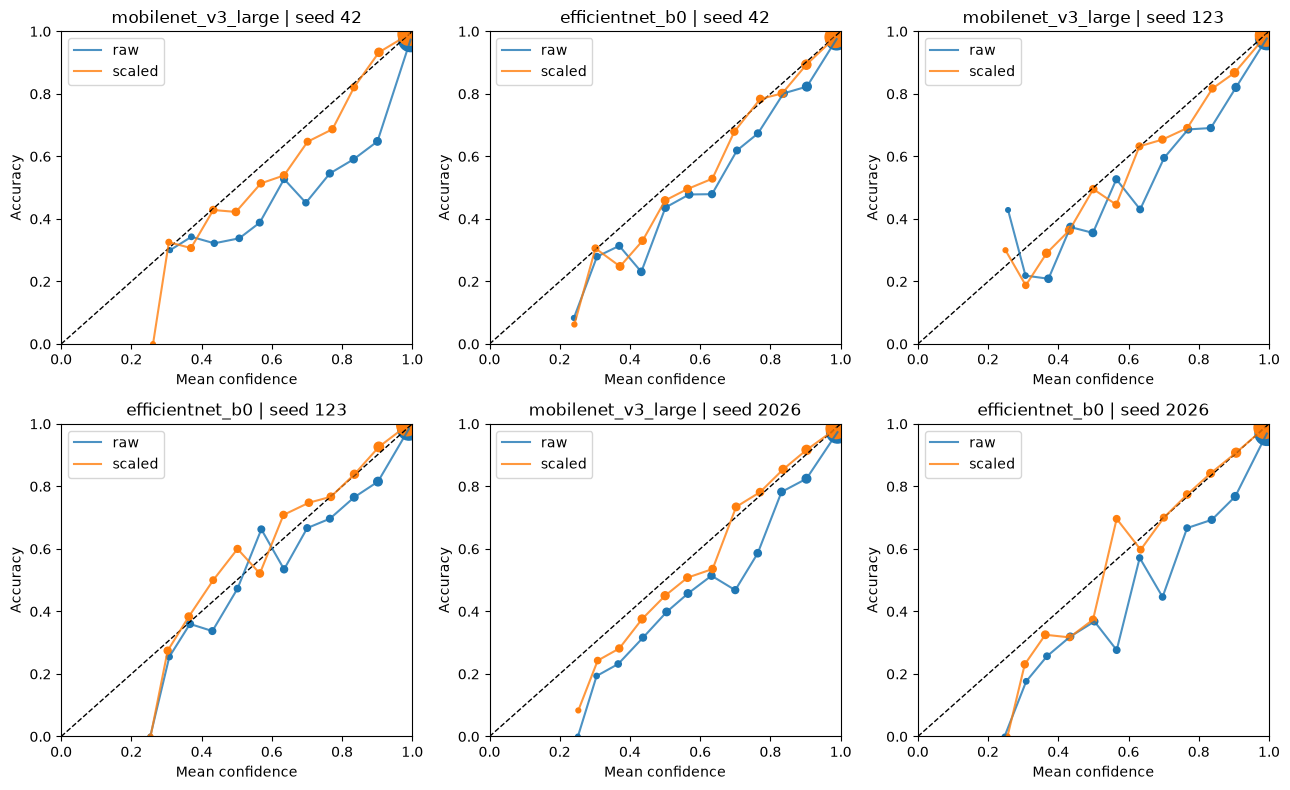

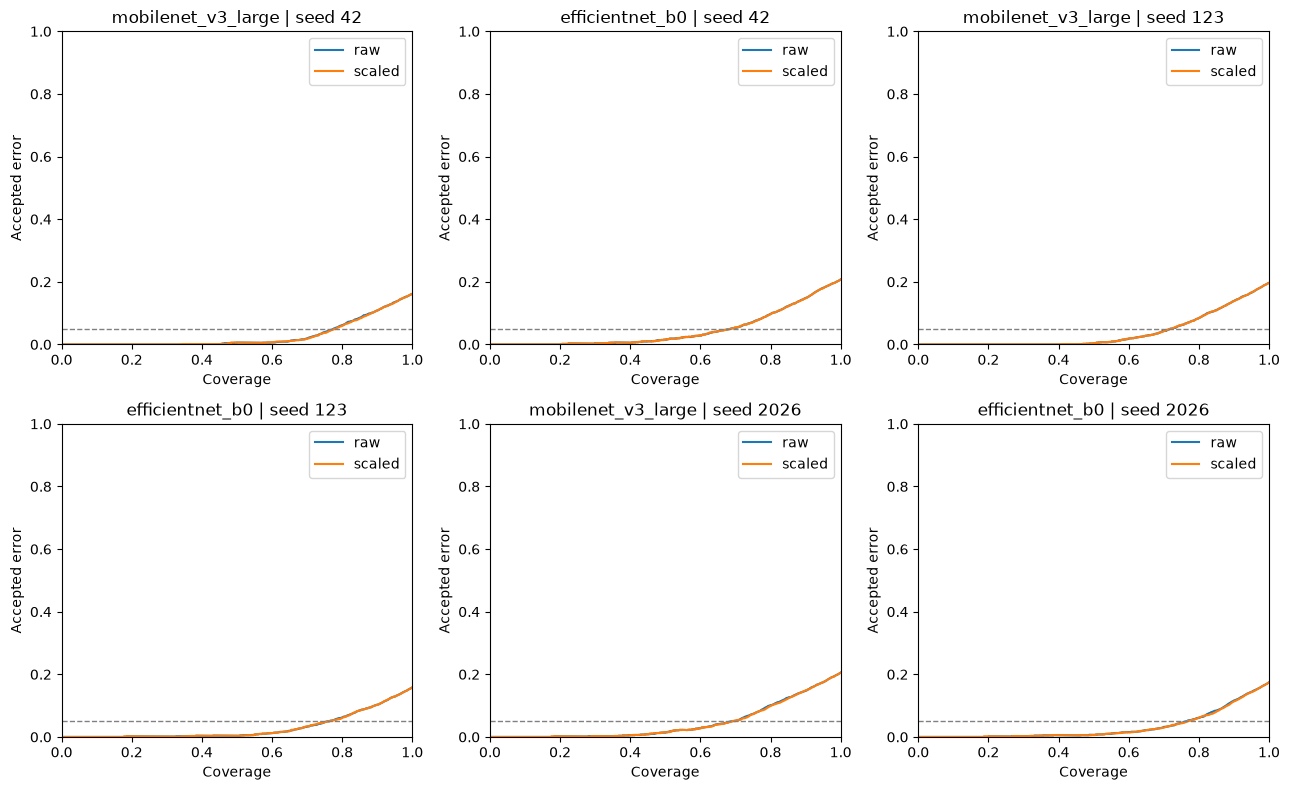

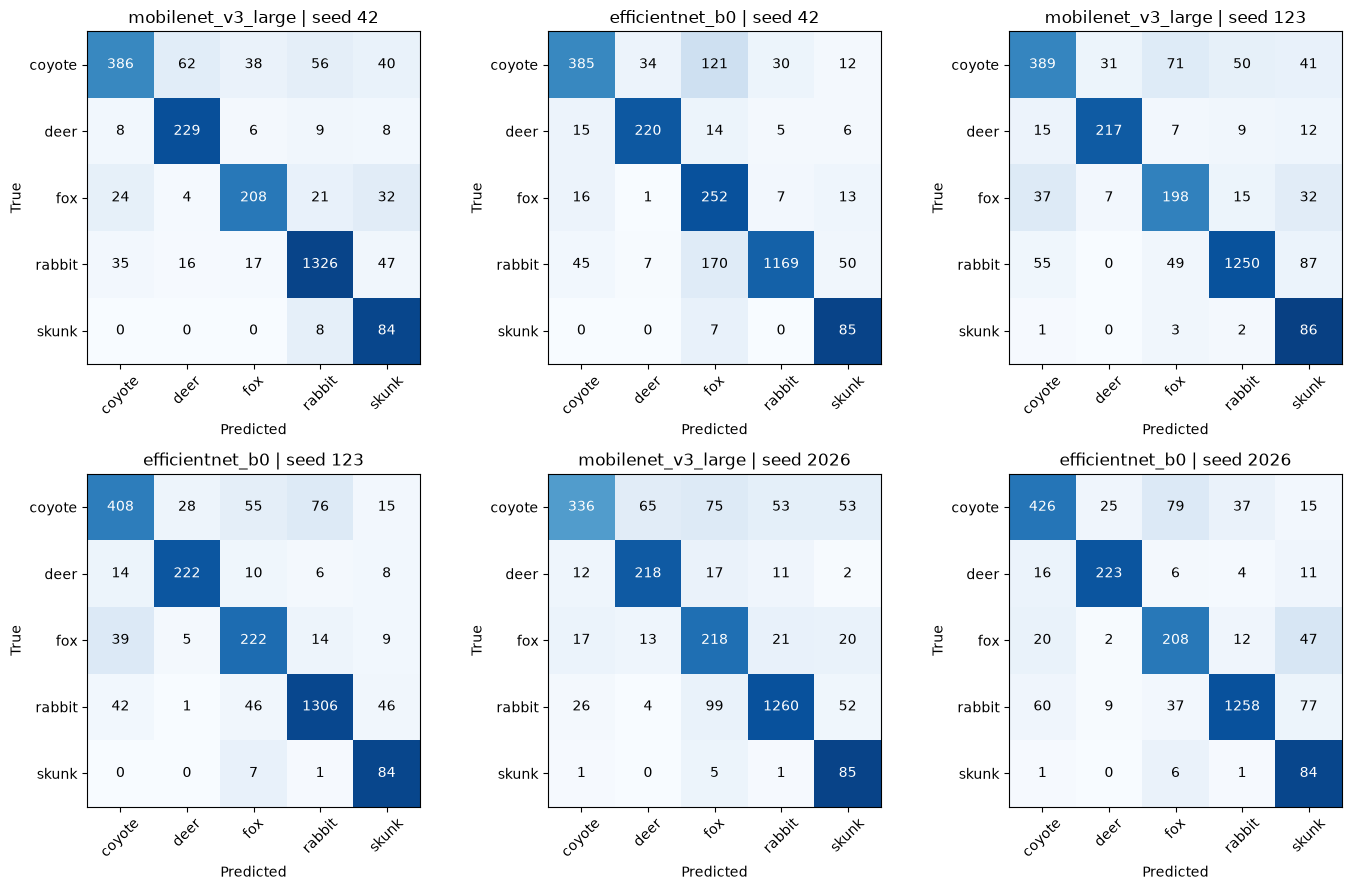

,model,seed,true_class,predicted_class,count
0,mobilenet_v3_large,42,coyote,coyote,386
1,mobilenet_v3_large,42,coyote,deer,62
2,mobilenet_v3_large,42,coyote,fox,38
3,mobilenet_v3_large,42,coyote,rabbit,56
4,mobilenet_v3_large,42,coyote,skunk,40
...,...,...,...,...,...
145,efficientnet_b0,2026,skunk,coyote,1
146,efficientnet_b0,2026,skunk,deer,0
147,efficientnet_b0,2026,skunk,fox,6
148,efficientnet_b0,2026,skunk,rabbit,1


In [8]:
fig,axes=plt.subplots(2,3,figsize=(13,8))
rel_tables=[]
for ax,(key,a) in zip(axes.flat,TEST.items()):
    ax.plot([0,1],[0,1],"k--",lw=1)
    for variant,T in [("raw",1.),("scaled",TEMPERATURES[key])]:
        rel=reliability(a["logits"],a["labels"],T,CFG["ece_bins"])
        rel_tables.append(rel.assign(model=key[0],seed=key[1],variant=variant))
        good=rel["count"]>0
        ax.plot(rel.loc[good,"confidence"],rel.loc[good,"accuracy"],label=variant,alpha=.8)
        ax.scatter(rel.loc[good,"confidence"],rel.loc[good,"accuracy"],s=10+rel.loc[good,"count"]*.15)
    ax.set(title=f"{key[0]} | seed {key[1]}",xlabel="Mean confidence",ylabel="Accuracy",xlim=(0,1),ylim=(0,1))
    ax.legend()
fig.tight_layout();fig.savefig(REPORT/"test_reliability.png",dpi=160);plt.show();plt.close(fig)
table("test_reliability_bins.csv",pd.concat(rel_tables,ignore_index=True))

fig,axes=plt.subplots(2,3,figsize=(13,8));risk_tables=[]
for ax,(key,a) in zip(axes.flat,TEST.items()):
    for variant,T in [("raw",1.),("scaled",TEMPERATURES[key])]:
        conf=probabilities(a["logits"],T)[0].max(1);order=np.argsort(-conf,kind="stable")
        ends=np.r_[np.flatnonzero(conf[order][:-1]!=conf[order][1:]),len(order)-1]
        risk=np.cumsum(a["logits"].argmax(1)[order]!=a["labels"][order])[ends]/(ends+1)
        cov=(ends+1)/len(order)
        ax.plot(cov,risk,label=variant)
        risk_tables.append(pd.DataFrame({"model":key[0],"seed":key[1],"variant":variant,"coverage":cov,"error":risk}))
    ax.axhline(CFG["target_error"],color="gray",ls="--",lw=1)
    ax.set(title=f"{key[0]} | seed {key[1]}",xlabel="Coverage",ylabel="Accepted error",xlim=(0,1),ylim=(0,1));ax.legend()
fig.tight_layout();fig.savefig(REPORT/"test_risk_coverage.png",dpi=160);plt.show();plt.close(fig)
table("test_risk_coverage.csv",pd.concat(risk_tables,ignore_index=True))

fig,axes=plt.subplots(2,3,figsize=(14,9));cm_rows=[]
for ax,(key,a) in zip(axes.flat,TEST.items()):
    cm=np.bincount(a["labels"]*K+a["logits"].argmax(1),minlength=K*K).reshape(K,K)
    row_sum=cm.sum(1,keepdims=True)
    normalized=np.divide(cm,row_sum,out=np.zeros_like(cm,dtype=float),where=row_sum>0)
    ax.imshow(normalized,vmin=0,vmax=1,cmap="Blues")
    for i in range(K):
        for j in range(K):
            ax.text(j,i,str(cm[i,j]),ha="center",va="center",color="white" if normalized[i,j]>.5 else "black")
            cm_rows.append({"model":key[0],"seed":key[1],"true_class":CLASSES[i],"predicted_class":CLASSES[j],"count":int(cm[i,j])})
    ax.set(xticks=range(K),yticks=range(K),xticklabels=CLASSES,yticklabels=CLASSES,
           title=f"{key[0]} | seed {key[1]}",xlabel="Predicted",ylabel="True")
    ax.tick_params(axis="x",rotation=45)
fig.tight_layout();fig.savefig(REPORT/"test_confusion_matrices.png",dpi=160);plt.show();plt.close(fig)
table("test_confusion_matrices.csv",cm_rows)


## 9. Report handoff and completion record
Generated notes state the actual protocol, temperatures, policy outcomes and test metrics. They explicitly retain overfitting, checkpoint-selection and detector-pretraining limitations. Report values from the generated CSVs rather than reading rounded graph labels. Save this executed notebook (Ctrl+S) so printed outputs and figures travel with your submission.


In [9]:
def plain_table(df):
    # Built-in text output avoids a new tabulate dependency.
    return "```text\n"+df.to_string(index=False,float_format=lambda x:f"{x:.4f}")+"\n```"
notes=f"""# Calibration and final evaluation — actual results
Generated {now()}. Evaluation hash: {EVAL_SHA}. Decision hash: {DECISION_SHA}.

## Method
All six notebook03 best-finetune checkpoints were retained. Positive scalar temperatures minimized calibration-camera image-weighted NLL, within fixed bounds [0.01,100]. No network weights were updated. Thresholds were independently chosen for raw and scaled maximum-class confidence on policy cameras, maximizing coverage subject to observed error <=5%, at least 100 accepted images and at least five accepted cameras. No feasible threshold means no automation. This is empirical threshold selection, not a certified error guarantee. Temperatures and policies were frozen before test inference.

The final test contains {len(test_frame)} event representatives from {C} classifier-held-out cameras. Image-weighted NLL, accuracy, five-class macro-F1, multiclass summed Brier and equal-width 15-bin top-label ECE were reported. ECE sensitivity uses 10/20 bins. Undefined accepted errors are left blank, not converted to zero. Thresholds were not modified using test outcomes.

## Temperatures (calibration NLL is fitted, not independent)
{plain_table(temperature_summary)}

## Policy outcomes (selection data)
{plain_table(policy_summary)}

## Final held-out test results
{plain_table(results)}

## Uncertainty
2,000 paired whole-test-camera bootstrap draws (seed {CFG['bootstrap_seed']}) provide percentile 95% intervals. Draws are shared across models, seeds and variants. Within each draw, all images of each sampled camera are retained, and metrics remain image-weighted. Comparisons average the three seed-specific differences. These intervals condition on fitted classifiers, calibration and policy rules; they do not include uncertainty from retraining, refitting, alternative camera splits or pretrained detector development. Accepted-error replicates with zero accepted images are undefined and counted in the interval tables. Seed means/std are descriptive training-randomness summaries, not camera uncertainty.

## Limitations and interpretation
Training curves showed a generalization gap and validation fluctuations. Early stopping selected the best fine-tuning checkpoint only; it did not compare against head-only checkpoints. In the recorded notebook03 outputs, fine-tuning improved validation NLL over the best head-only checkpoint in five of six runs; EfficientNet seed42 had head NLL 0.4264 versus selected fine-tune NLL 0.4427. We retained the fixed selection rule. Small-batch BatchNorm adaptation is a possible contributor to instability, not an isolated causal finding. Architectures use different pretrained configurations under a shared training recipe; this is not a causal architecture-only experiment.

Inputs used official precomputed raw MDv5a predictions, animal threshold 0.20, highest-confidence box, 5% margin, and full-frame fallback; MegaDetector was not run locally. Its historical training includes Caltech, so detector holdout is not guaranteed. Classifier cameras were separated. One image represents each selected event; this is a five-category closed-set classification study, not an open-world detector evaluation or a full replication of Dussert et al. Class support, camera distribution shift and label/box errors can limit generalization. Global temperatures/thresholds do not guarantee class-specific calibration or accepted error. Temperature scaling preserves predicted labels and cannot remove classification mistakes. Policy/test target failures must be reported alongside coverage.

## Files
Main tables: test_results.csv, temperature_summary.csv, policy_summary.csv, test_per_class.csv, test_seed_summary.csv. Uncertainty: test_camera_bootstrap_intervals.csv and paired_camera_bootstrap_contrasts.csv. Figures: test_reliability.png, test_risk_coverage.png, test_confusion_matrices.png. Diagnostics: ece_bin_sensitivity.csv, test_reliability_bins.csv, test_predictions.csv. Protocol/provenance: evaluation_protocol.json, frozen_calibration_and_policies.json, test_exports.json. Raw test logits remain in models/five_categories_v1/evaluation_v1. Keep checkpoints and inputs available locally for reproducibility even if omitted from the Git repository.

## References
Guo et al. (2017), On Calibration of Modern Neural Networks. https://proceedings.mlr.press/v70/guo17a.html
Dussert et al. (2025), Being confident in confidence scores: calibration in deep learning models for camera trap image sequences. https://doi.org/10.1002/rse2.412
PyTorch checkpoint loading: https://docs.pytorch.org/docs/stable/generated/torch.load.html
LILA MegaDetector outputs: https://lila.science/megadetector-results-for-camera-trap-datasets/
"""
write(REPORT/"FINAL_METHODS_AND_RESULTS.md",notes)
write(REPORT/"completion.json",jtext({"time_utc":now(),"evaluation_sha256":EVAL_SHA,
    "decisions_sha256":DECISION_SHA,"completed_runs":len(TEST),"test_images":len(test_frame),
    "test_cameras":C,"bootstrap_repeats":CFG["bootstrap_repeats"],"test_used_for_fitting":False,
    "outputs":{p.name:sha(p) for p in sorted(REPORT.iterdir()) if p.is_file() and p.name!="completion.json"}}))
print("Completed evaluation for all six runs.")
print("Report tables, plots and methods:",REPORT)
print("Save this executed notebook with Ctrl+S.")


Completed evaluation for all six runs.
Report tables, plots and methods: /home/fia/Schreibtisch/ml_project_final/wildlife_confidence_project/reports/five_categories_v1/evaluation_v1
Save this executed notebook with Ctrl+S.
